<a href="https://colab.research.google.com/github/Alfredsamson/Diabetes-predication-with-Xai/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")


from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from scipy import stats


In [ ]:
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-2-91874b305a32>", line 2, in <cell line: 2>
    drive.mount('/content/drive/')
  File "/usr/local/lib/python3.10/dist-packages/google/colab/drive.py", line 103, in mount
    return _mount(
  File "/usr/local/lib/python3.10/dist-packages/google/colab/drive.py", line 132, in _mount
    _message.blocking_request(
  File "/usr/local/lib/python3.10/dist-packages/google/colab/_message.py", line 176, in blocking_request
    return read_reply_from_input(request_id, timeout_sec)
  File "/usr/local/lib/python3.10/dist-packages/google/colab/_message.py", line 96, in read_reply_from_input
    time.sleep(0.025)
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/IPyth

TypeError: ignored

In [ ]:
sugar='/content/drive/MyDrive/Dataset of Diabetes .csv'

In [ ]:
project=pd.read_csv(sugar)

In [ ]:
project.shape

(1000, 14)

In [ ]:
project.head()

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


In [ ]:
project.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null   int64  
 2   Gender     1000 non-null   object 
 3   AGE        1000 non-null   int64  
 4   Urea       1000 non-null   float64
 5   Cr         1000 non-null   int64  
 6   HbA1c      1000 non-null   float64
 7   Chol       1000 non-null   float64
 8   TG         1000 non-null   float64
 9   HDL        1000 non-null   float64
 10  LDL        1000 non-null   float64
 11  VLDL       1000 non-null   float64
 12  BMI        1000 non-null   float64
 13  CLASS      1000 non-null   object 
dtypes: float64(8), int64(4), object(2)
memory usage: 109.5+ KB


In [ ]:
project.describe()

,ID,No_Pation,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
count,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,340.500000,2.705514e+05,53.528000,5.124743,68.943000,8.281160,4.862820,2.349610,1.204750,2.609790,1.854700,29.578020
std,240.397673,3.380758e+06,8.799241,2.935165,59.984747,2.534003,1.301738,1.401176,0.660414,1.115102,3.663599,4.962388
min,1.000000,1.230000e+02,20.000000,0.500000,6.000000,0.900000,0.000000,0.300000,0.200000,0.300000,0.100000,19.000000
25%,125.750000,2.406375e+04,51.000000,3.700000,48.000000,6.500000,4.000000,1.500000,0.900000,1.800000,0.700000,26.000000
50%,300.500000,3.439550e+04,55.000000,4.600000,60.000000,8.000000,4.800000,2.000000,1.100000,2.500000,0.900000,30.000000
75%,550.250000,4.538425e+04,59.000000,5.700000,73.000000,10.200000,5.600000,2.900000,1.300000,3.300000,1.500000,33.000000
max,800.000000,7.543566e+07,79.000000,38.900000,800.000000,16.000000,10.300000,13.800000,9.900000,9.900000,35.000000,47.750000


Text(0.5, 0, 'Diabtes Diagnosis Rate')

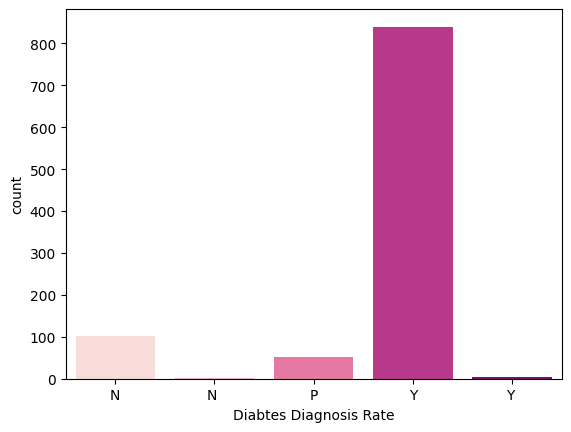

In [ ]:
sns.countplot(project, x='CLASS', palette= 'RdPu')
plt.xlabel("Diabtes Diagnosis Rate")

In [ ]:
project['CLASS'].unique()

array(['N', 'N ', 'P', 'Y', 'Y '], dtype=object)

In [ ]:
project['CLASS'] = project['CLASS'].replace(['Y '], 'Y')

In [ ]:
project['Gender'].unique()

array(['F', 'M', 'f'], dtype=object)

In [ ]:
project['Gender'] = project['Gender'].replace(['f'], 'F')

In [ ]:
project['CLASS'] = project['CLASS'].replace(['N '], 'N')

Text(0.5, 0, 'Diabtes Diagnosis Rate')

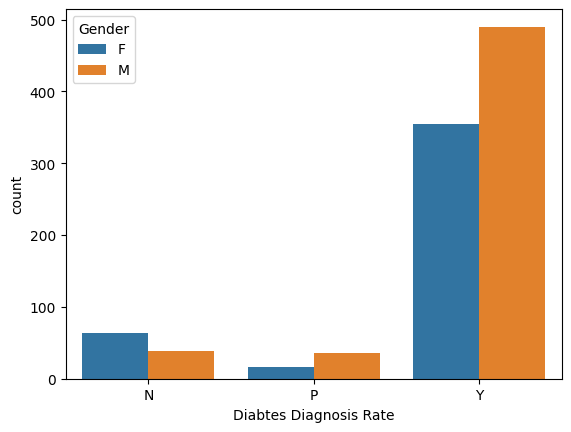

In [ ]:
sns.countplot(project, x='CLASS', hue='Gender')
plt.xlabel("Diabtes Diagnosis Rate")

In [ ]:
#replace gender and class with numerical values
project['Gender'].replace({'F':1,'M':0},inplace=True)

In [ ]:
project['CLASS'].replace({'N':0,'Y':1,'P':2},inplace=True)

In [ ]:
from scipy import stats

In [ ]:
test = project[['AGE', 'Urea', 'Cr', 'HbA1c','Chol','TG','HDL','LDL','VLDL','BMI']]
z = np.abs(stats.zscore(test))
data = project[(z < 9).all(axis=1)]

In [ ]:
numerical_columns = ['AGE', 'Urea', 'Cr', 'HbA1c','Chol','TG','HDL','LDL','VLDL','BMI']

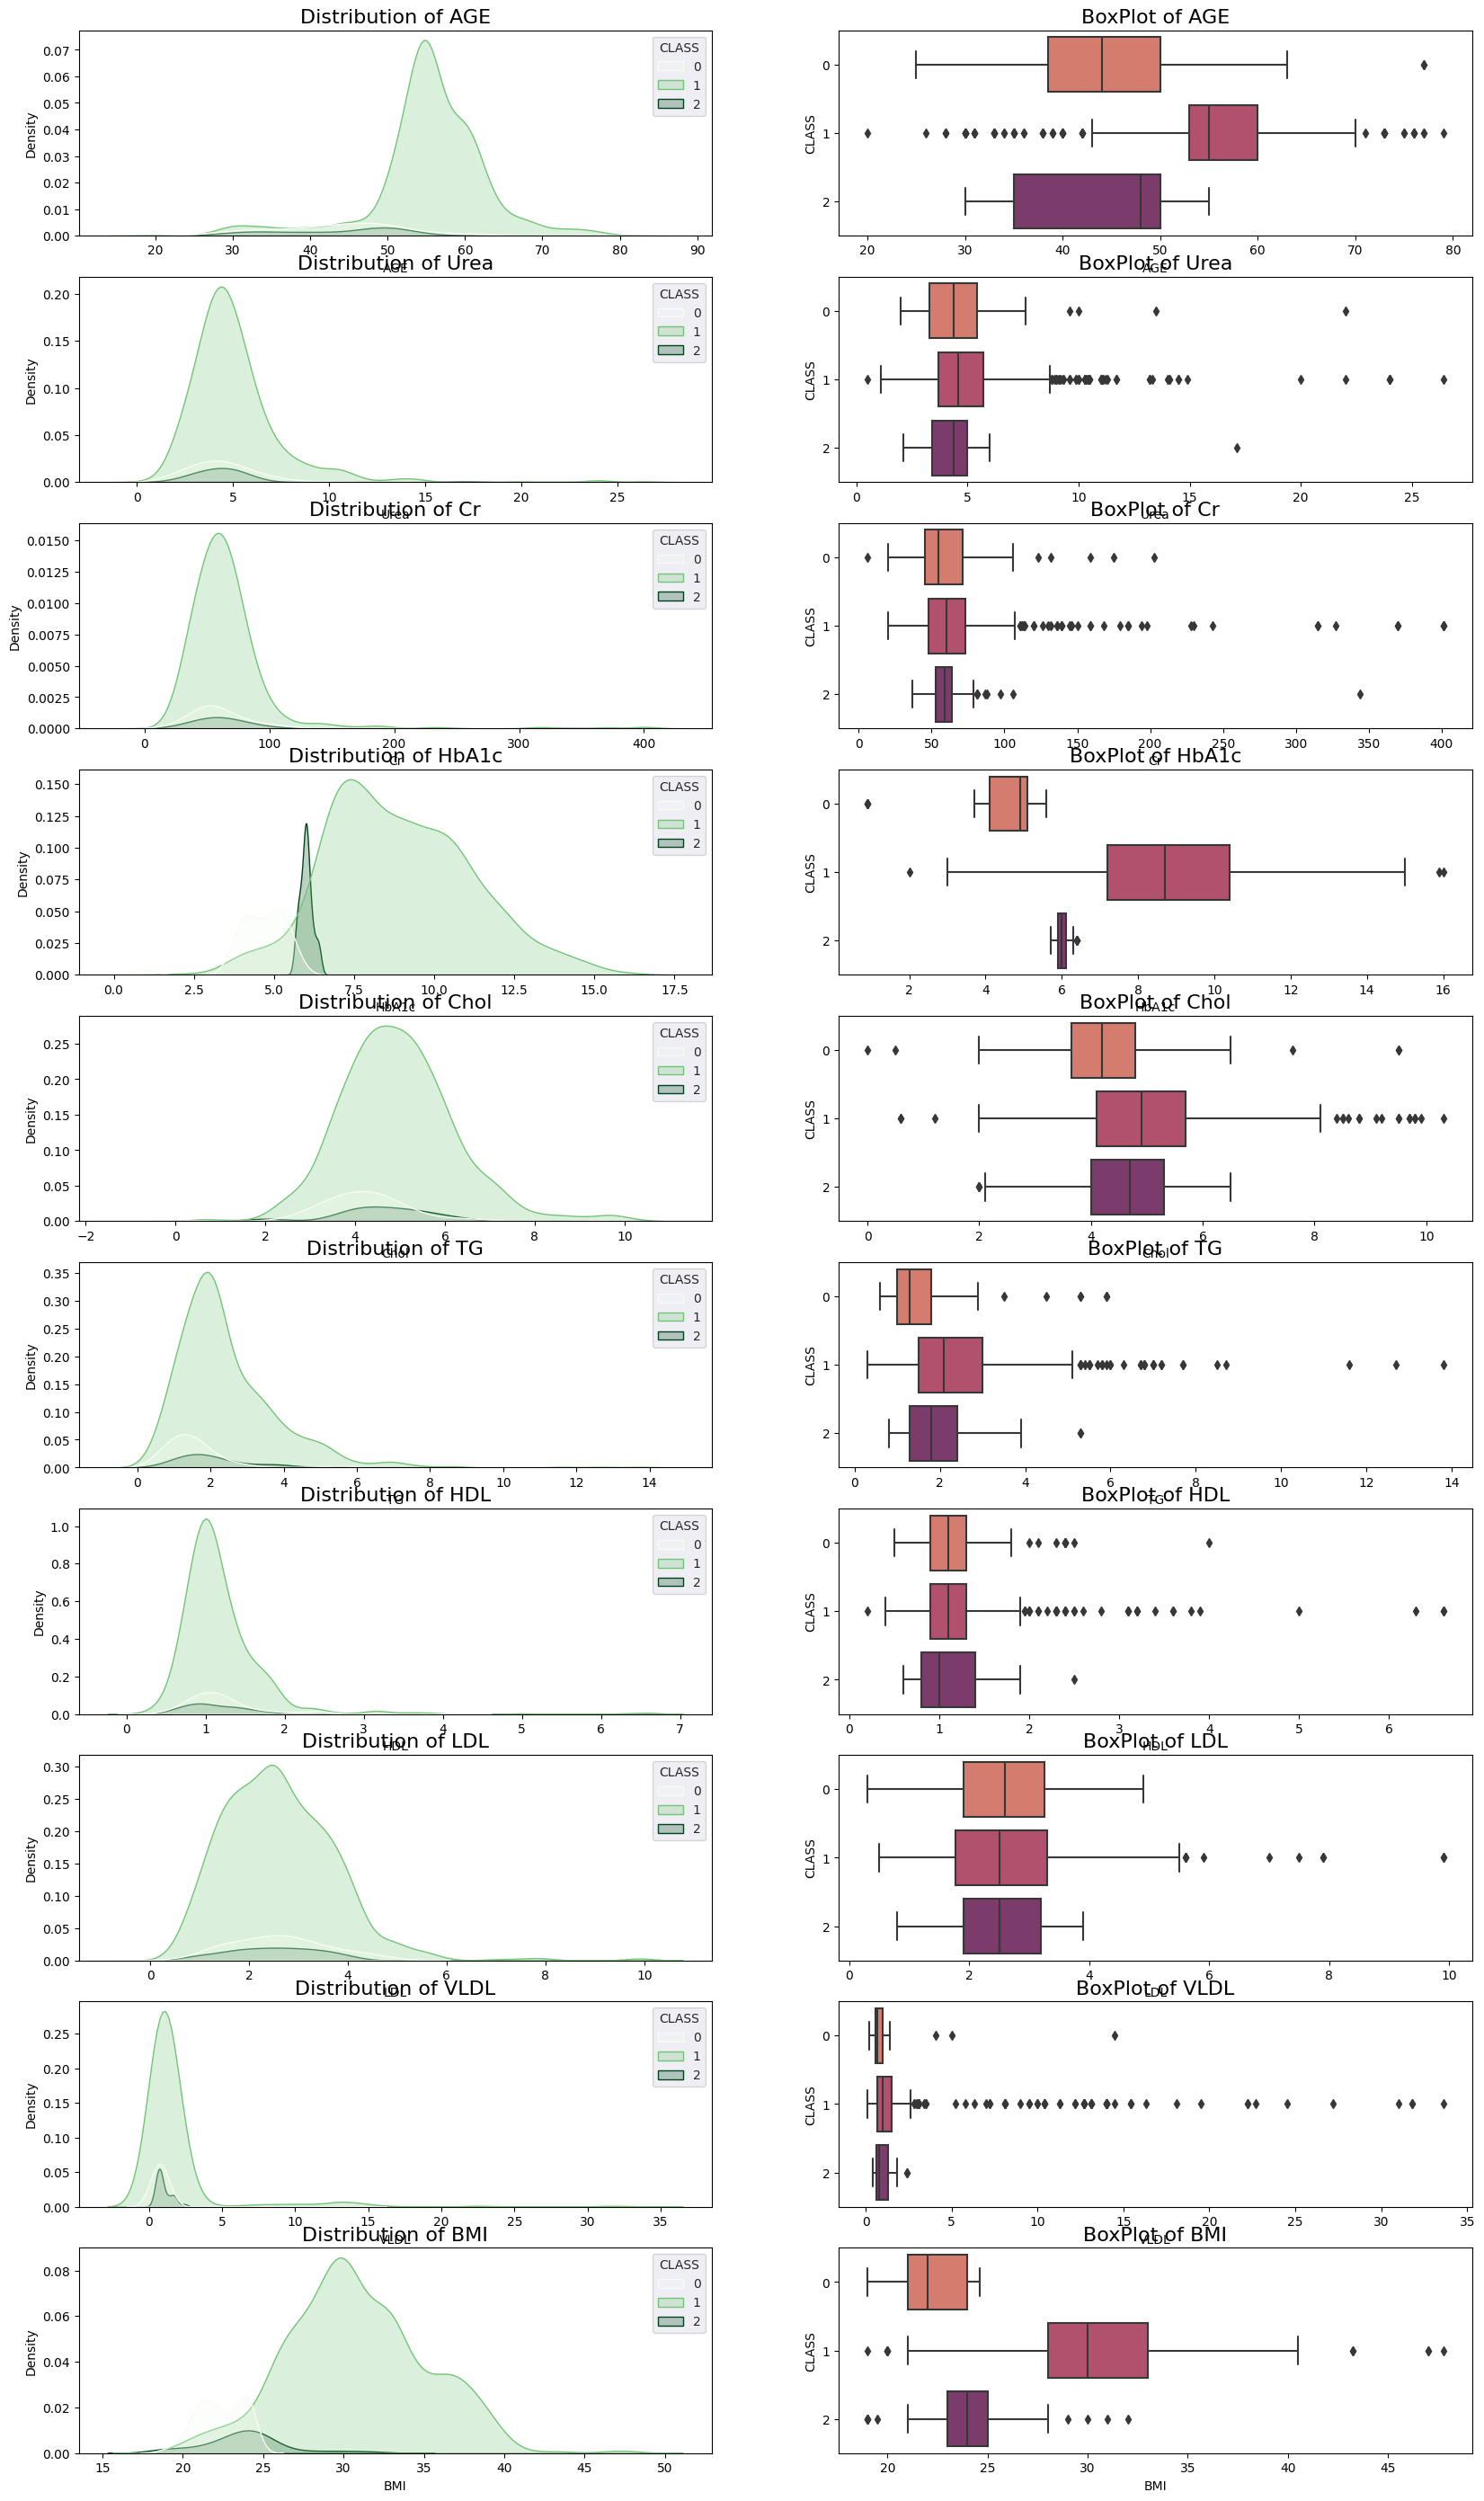

In [ ]:
fig, axes = plt.subplots(10,2, figsize=(20,35))
sns.set_style('darkgrid')
idx = 0
for col in (numerical_columns):
    sns.kdeplot(data=data, x=col, palette='Greens',fill=True , hue='CLASS',
                ax=axes[idx][0]).set_title(f'Distribution of {col}', fontsize='16')
    sns.boxplot(data=data, x=col, palette='flare' , y='CLASS', orient='h',
                ax=axes[idx][1]).set_title(f'BoxPlot of {col}', fontsize='16')
    idx +=1
plt.show()

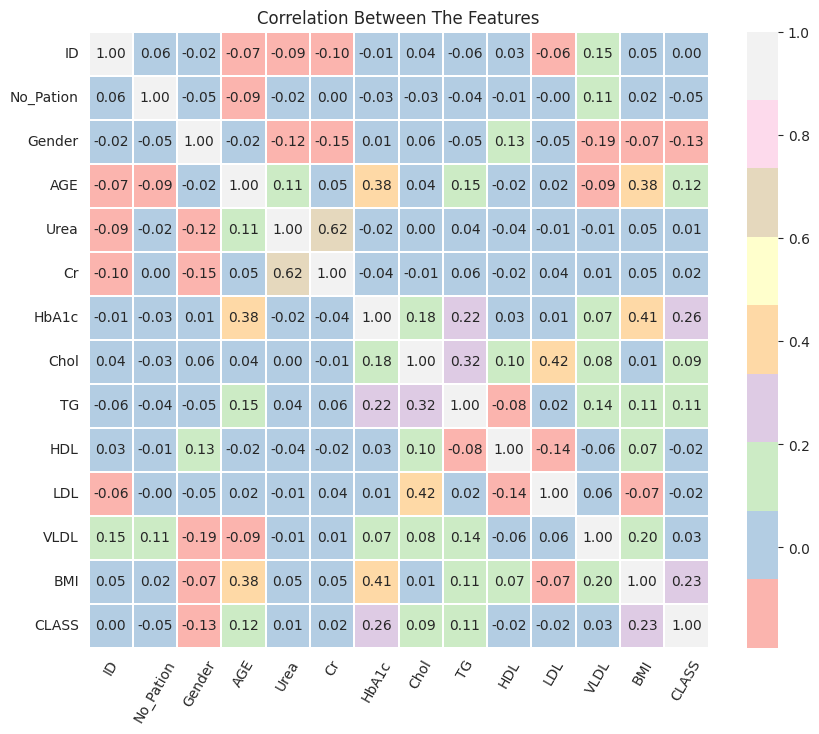

In [ ]:
fig=plt.gcf()
fig.set_size_inches(10,8)
plt.title('Correlation Between The Features')
a = sns.heatmap(project.corr(), annot=True, cmap='Pastel1', fmt='.2f', linewidths=0.2)
a.set_xticklabels(a.get_xticklabels(), rotation=60)
a.set_yticklabels(a.get_yticklabels())
plt.show()

In [ ]:
y = project['CLASS'].values
X =project.drop('CLASS', axis=1)



In [ ]:
Features = ['Urea', 'Cr', 'HbA1c','Chol','TG','HDL','LDL','VLDL','BMI']

In [ ]:
X=project[Features].values

In [ ]:
pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=68154e38972cdeb267c4abb62b9f4d5908b00f51f6a046f19209280cb6e34a2d
  Stored in directory: /root/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime


In [ ]:
import lime
import lime.lime_tabular
import lightgbm as lgb

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import tree, model_selection, metrics

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=45)


In [ ]:
rf = RandomForestClassifier(max_depth = 15, min_samples_split=0.05,min_samples_leaf =9)
rf.fit(X_train,y_train)
yhat = rf.predict(X_test)
test_score = rf.score(X_test, y_test)
print('Test score is : {}'.format(test_score))


Test score is : 0.9666666666666667


In [ ]:
print(metrics.classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        33
           1       0.97      1.00      0.98       252
           2       1.00      0.47      0.64        15

    accuracy                           0.97       300
   macro avg       0.98      0.81      0.86       300
weighted avg       0.97      0.97      0.96       300



# Logistic Regression

In [ ]:
import sklearn
from sklearn import linear_model
from sklearn.linear_model import LinearRegression

In [ ]:
lm = linear_model.LogisticRegression(multi_class='ovr', solver='liblinear')
lm.fit(X_train, y_train)

LogisticRegression(multi_class='ovr', solver='liblinear')

In [ ]:
lm.score(X_test, y_test)

0.8866666666666667

In [ ]:
print(metrics.classification_report(y_test, lm.predict(X_test)))

              precision    recall  f1-score   support

           0       0.79      0.58      0.67        33
           1       0.89      0.98      0.94       252
           2       0.00      0.00      0.00        15

    accuracy                           0.89       300
   macro avg       0.56      0.52      0.53       300
weighted avg       0.84      0.89      0.86       300



# XGBoost

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb = XGBClassifier(max_depth = 4)

In [ ]:
xgb.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

In [ ]:
xgb.score(X_test, y_test)

0.99

In [ ]:
print(metrics.classification_report(y_test, xgb.predict(X_test)))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        33
           1       0.99      1.00      0.99       252
           2       1.00      0.93      0.97        15

    accuracy                           0.99       300
   macro avg       0.99      0.97      0.98       300
weighted avg       0.99      0.99      0.99       300



In [ ]:
from sklearn import svm

In [ ]:
clf = svm.SVC(decision_function_shape='ovr',probability=True)

In [ ]:
clf.fit(X_train, y_train)

SVC(probability=True)

In [ ]:
clf.score(X_test, y_test)

0.84

In [ ]:
print(metrics.classification_report(y_test, clf.predict(X_test)))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        33
           1       0.84      1.00      0.91       252
           2       0.00      0.00      0.00        15

    accuracy                           0.84       300
   macro avg       0.28      0.33      0.30       300
weighted avg       0.71      0.84      0.77       300



# Lime Explainer

In [ ]:
feature_names = ['Urea', 'Cr', 'HbA1c','Chol','TG','HDL','LDL','VLDL','BMI','CLASS']
class_names =[0,1,2]

In [ ]:
import lime.lime_tabular

In [ ]:
# Print shapes to confirm they are what you expect
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

# Generate a random index within the bounds of X_test's size
i = np.random.randint(0, X_test.shape[0])
print("Random index selected:", i)

# Reshape X_test[i] if necessary
#instance_to_explain = X_test[i].reshape(1, -1)

# Explain the instance
#exp = explainer.explain_instance(X_test[i], lm.predict_proba, num_features=3, top_labels=1)


X_train shape: (700, 9)
X_test shape: (300, 9)
Random index selected: 10


In [ ]:
import sklearn
import lime
import lime.lime_tabular
from sklearn.pipeline import make_pipeline

In [ ]:
feature_names = ['Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI',"Class"]
class_names=[0,1,2]

# Lime Explainer


In [ ]:
explainer = lime.lime_tabular.LimeTabularExplainer(X_train, feature_names=feature_names, class_names=class_names)
#i = np.random.randint(0, X_test.shape[0])

In [ ]:
exp = explainer.explain_instance(X_test[i], lm.predict_proba, num_features=9, top_labels=1)
exp.show_in_notebook(show_table=True, show_all=False)

In [ ]:
exp = explainer.explain_instance(X_test[i], rf.predict_proba, num_features=9, top_labels=1)
exp.show_in_notebook(show_table=True, show_all=False)

In [ ]:
exp = explainer.explain_instance(X_test[i], xgb.predict_proba, num_features=9, top_labels=1)
exp.show_in_notebook(show_table=True, show_all=False)

In [ ]:
exp = explainer.explain_instance(X_test[i], clf.predict_proba, num_features=9, top_labels=1)
exp.show_in_notebook(show_table=True, show_all=False)